In [1]:
import json
import os.path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.font_manager import FontProperties


In [2]:
# ---------- Config ----------
model = "Qwen/Qwen2.5-Coder-32B"
short_model_name = model.split("/")[-1]

model_results_dir = f"../model_results/{short_model_name}"
output_dir = "Intro"

if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# JSON file containing perplexity results
json_file = f"{model_results_dir}/perplexity_results.json"

# keys for the JSON file
clean_key = "9-clean-v1"
confusing_key = "9-obf-v1"

# font properties for the plot
monospace_font = "Courier New"
pixels_per_token = 0.28
base_fontsize = 13
bar_fontsize = 9
bar_color = "#D62728"  # red tone
bar_linewidth = 0.4

# highlight token index ranges here (inclusive, zero-based)
highlight_ranges_clean = [(11, 12)]
highlight_ranges_conf = [(11, 13)]

In [3]:
# create sample EEG data for plotting
np.random.seed(42)  # For reproducibility

# Time vector for 100 samples over the 0.4 to 0.8 seconds window
t = np.linspace(0.4, 0.8, 100)
# Clean snippet: mostly flat or slightly negative baseline with low amplitude slow oscillations + noise
clean_signal = (
        -0.2
        + 0.01 * np.sin(2 * np.pi * 5 * t)  # slow oscillation (5 Hz)
        + 0.05 * np.sin(2 * np.pi * 1 * t)  # very slow 1 Hz oscillation
)

# Confusing snippet: positive baseline with a prominent peak (e.g., Gaussian bump) + oscillations + noise
peak_center = 0.6  # seconds, near middle of the window
peak_width = 0.05

# Gaussian peak function
gaussian_peak = np.exp(-((t - peak_center) ** 2) / (2 * peak_width ** 2))

confusing_signal = (
        0.6  # positive baseline
        + 0.6 * gaussian_peak  # strong peak reaching ~1 at center
        + 0.1 * np.sin(2 * np.pi * 10 * t)  # slower oscillation (2 Hz)
)

# scale signals to be in the range of -10 to 10 for better visibility
clean_signal = clean_signal / np.max(np.abs(clean_signal)) * 10
confusing_signal = confusing_signal / np.max(np.abs(confusing_signal)) * 10

averaged_trials = {
    clean_key: [clean_signal],
    confusing_key: [confusing_signal]
}
std_trials = None
max_trials = None


In [4]:
def load_snippet(json_path, key):
    with open(json_path, "r") as f:
        data = json.load(f)
    entry = data[key]
    return entry["code"], entry["tokens"], entry["results"]


def get_perplexities(results):
    return [r["perplexity"] for r in results]


import matplotlib.patches as patches


def plot_code_block_with_aoi(ax, code, fontsize, tokens, highlight_ranges=None, snippet_type="clean", padding=0.01):
    ax.axis("off")

    font_prop = FontProperties(family="monospace", size=fontsize)
    line_spacing = 1.5

    code_lines = code.splitlines()

    # Inverted transform for converting display to axes coords
    inv = ax.transAxes.inverted()

    y_cursor = 1  # start at top (axes coords)

    token_idx = 0
    token_positions = []

    # Calculate single char height in display coords
    sample_char = "A"
    tp = ax.text(0, 0, sample_char, fontproperties=font_prop)
    renderer = ax.figure.canvas.get_renderer()
    bbox = tp.get_window_extent(renderer=renderer)
    char_height_disp = bbox.height
    tp.remove()

    # Convert char height from display to axes coords for line height
    p0 = inv.transform((0, 0))
    p1 = inv.transform((0, char_height_disp))
    line_height = (p1[1] - p0[1]) * line_spacing

    for line in code_lines:
        x_cursor = padding

        # Collect tokens that belong to this line
        line_length = len(line)
        length_sum = 0
        line_tokens = []
        while token_idx < len(tokens) and length_sum < line_length:
            t = tokens[token_idx].replace("\n", "")
            length_sum += len(t)
            line_tokens.append(tokens[token_idx])
            token_idx += 1

        for t in line_tokens:
            t_stripped = t.replace("\n", "")
            if not t_stripped:
                continue

            # Draw token text individually at (x_cursor, y_cursor) in axes coords
            txt = ax.text(x_cursor, y_cursor, t_stripped,
                          fontproperties=font_prop,
                          va='top', ha='left',
                          transform=ax.transAxes)

            # Get bounding box in display coords
            bbox = txt.get_window_extent(renderer=ax.figure.canvas.get_renderer())

            # Convert bbox corners from display to axes coords
            fig = ax.figure
            fig_height_disp = fig.bbox.height

            x0_disp = bbox.x0
            y0_disp = bbox.y0
            x1_disp = bbox.x1
            y1_disp = bbox.y1

            # Invert y because display y coords go from top to bottom
            y0_disp_inverted = fig_height_disp - y0_disp
            y1_disp_inverted = fig_height_disp - y1_disp

            x0_ax, y0_ax = inv.transform((x0_disp, y0_disp_inverted))
            x1_ax, y1_ax = inv.transform((x1_disp, y1_disp_inverted))

            token_positions.append([x0_ax, y0_ax, x1_ax, y1_ax])

            x_cursor = x1_ax + padding  # advance cursor with padding in axes coords

        y_cursor -= line_height

    # Set colors for AOI boxes
    if snippet_type == "clean":
        edge_color = "#1F77B4"  # blue
        fill_color = "#ADD8E6"  # light blue
    else:
        edge_color = "#D62728"  # red
        fill_color = "#F4C6C5"  # light red

    # Draw AOI boxes if any
    if highlight_ranges:
        for start, end in highlight_ranges:
            if start < 0 or end >= len(token_positions) or start > end:
                continue

            x0 = min(token_positions[i][0] for i in range(start, end + 1))
            x1 = max(token_positions[i][2] for i in range(start, end + 1))
            y0 = min(token_positions[i][1] for i in range(start, end + 1))
            y1 = max(token_positions[i][3] for i in range(start, end + 1))

            # Add padding and clamp to axes limits
            x0_p = max(0, x0 - padding)
            y0_p = max(0, y0 - padding) + 0.2
            x1_p = min(1, x1 + padding)
            y1_p = min(1, y1 + padding)

            width = x1_p - x0_p
            height = line_height

            rect = patches.Rectangle(
                (x0_p, y0_p), width, height,
                linewidth=1.5,
                edgecolor=edge_color,
                facecolor=fill_color,
                alpha=0.4,
                transform=ax.transAxes,
                joinstyle='round',
                capstyle='round'
            )
            ax.add_patch(rect)

    # Adjust axes limits tightly
    ax.set_xlim(0, 1)
    ax.set_ylim(y_cursor, 1)


def plot_token_bars(ax, tokens, perplexities, fontsize, highlight_ranges=None, snippet_type="clean", label=False,
                    ymax=None):
    """
    Plot token bars with log-scaled perplexity values.
    highlight_ranges: list of (start_idx, end_idx) tuples to highlight tokens in these ranges.
    """
    font_prop = FontProperties(family="monospace", size=fontsize)

    log_pplx = [np.log1p(p) for p in perplexities]
    max_log = max(log_pplx) if ymax is None else ymax
    x = np.arange(len(tokens))

    # Define colors based on snippet type
    if snippet_type == "clean":
        base_fill = "#D3D3D3"  # light grey for non-highlight
        base_edge = "none"
        highlight_fill = "#1F77B4"  # blue
        highlight_fill = highlight_fill + "CC"  # add transparency with alpha hex (CC ~ 80% opacity)
        highlight_edge = "none"  # darker blue

    else:  # confusing snippet
        base_fill = "#D3D3D3"  # light grey for non-highlight
        base_edge = "none"
        highlight_fill = "#D62728"  # red
        highlight_fill = highlight_fill + "CC"  # add transparency with alpha hex (CC ~ 80% opacity)
        highlight_edge = "none"  # dark red

    # Prepare colors per bar
    colors = [base_fill] * len(tokens)
    edges = [base_edge] * len(tokens)

    if highlight_ranges:
        for start, end in highlight_ranges:
            for i in range(start, end + 1):
                if 0 <= i < len(tokens):
                    colors[i] = highlight_fill
                    edges[i] = highlight_edge

    # Draw bars individually to assign different colors
    for i in range(len(tokens)):
        ax.bar(x[i], log_pplx[i], color=colors[i], edgecolor=edges[i], linewidth=0.7, width=0.8)

    ax.set_ylim(0, max_log * 1.1)
    ax.set_xlim(-0.5, len(tokens) - 0.5)

    # Subtle horizontal grid lines
    ax.yaxis.grid(True, linestyle='--', alpha=0.3, linewidth=0.6)

    # Token labels rotated 90 degrees, below bars
    # for i, token in enumerate(tokens):
    #    ax.text(x[i], -max_log * 0.07, token.replace("\n", "\\n"),
    #            rotation=90, fontsize=fontsize, ha="center",
    #            va="top", family=monospace_font)

    for i, token in enumerate(tokens):
        if any(start <= i <= end for start, end in highlight_ranges):
            ax.text(
                x[i], -max_log * 0.07, token.replace("\n", "\\n"),
                rotation=0, ha="center",
                va="top", fontproperties=font_prop
            )

    # Remove spines except bottom
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color(base_edge)
    ax.spines["bottom"].set_linewidth(0.8)

    # remove x-axis ticks and labels
    ax.set_xticks(x)
    ax.set_xticklabels([])
    ax.tick_params(axis='x', length=0)
    ax.xaxis.set_label_position('top')
    ax.set_xlabel("Tokens", fontsize=fontsize, labelpad=10)

    # Remove y-axis ticks and labels
    ax.set_yticks([])
    if label:
        ax.set_ylabel("LLM\nPerplexity", fontsize=fontsize)
    ax.tick_params(axis='y', length=0)

    # Slight padding below bars for labels
    ax.margins(y=0.2)


def plot_eeg(ax, signal, t_start=0.4, t_end=0.8, snippet_type="clean", label=False):
    n = len(signal)
    t = np.linspace(t_start, t_end, n)
    if snippet_type == "clean":
        color = "#1F77B4"  # blue
    else:
        color = "#D62728"  # red
    # scale signal to be from -10 to 10 for better visibility
    signal = signal / np.max(np.abs(signal)) * 10

    ax.plot(t, signal, lw=1.2, color=color)
    ax.set_xlim(t_start, t_end)

    sig_min, sig_max = signal.min(), signal.max()
    abs_max = max(abs(sig_min), abs(sig_max))
    margin = 0.1 * abs_max if abs_max > 0 else 0.1

    # Set symmetric y-limits around zero
    ax.set_ylim(-abs_max - margin, abs_max + margin)

    # Draw zero line
    ax.axhline(0, color='gray', lw=0.8, linestyle='--', alpha=0.6)

    # Minimal styling for research paper
    # ax.grid(True, linewidth=0.3, alpha=0.3)
    ax.tick_params(labelsize=8, length=3)
    ax.set_xlabel("Time (s)", fontsize=9)
    ax.set_xticks([0.4, 0.5, 0.6, 0.7, 0.8])
    if label:
        ax.set_ylabel(r"Mean FRP ($\mu$V)", fontsize=9)
    else:
        # remove y ticks and labels
        ax.set_yticks([])


from matplotlib.lines import Line2D


def draw_zoom_lines(fig, ax_src, ax_dst, start_idx, end_idx, token_count, color, pad=0.5):
    # Clamp padded indices
    padded_start = max(0, start_idx - pad)
    padded_end = min(token_count - 1, end_idx + pad)

    x_start = padded_start / max(token_count - 1, 1) - 0.01
    x_end = padded_end / max(token_count - 1, 1) - 0.01

    # Top Y in axes coords
    y_src = -0.1
    y_dst = 1.0

    # Convert from axes to figure coordinates
    src_start_fig = ax_src.transAxes.transform((x_start, y_src))
    src_end_fig = ax_src.transAxes.transform((x_end, y_src))
    dst_left_fig = ax_dst.transAxes.transform((0, y_dst))
    dst_right_fig = ax_dst.transAxes.transform((1, y_dst))

    # Transform to figure coordinates
    inv = fig.transFigure.inverted()
    p1 = inv.transform(src_start_fig)
    p2 = inv.transform(dst_left_fig)
    p3 = inv.transform(src_end_fig)
    p4 = inv.transform(dst_right_fig)

    # Create two dashed lines: start->left, end->right
    line1 = Line2D([p1[0], p2[0]], [p1[1], p2[1]], transform=fig.transFigure,
                   color=color, linestyle='--', linewidth=0.8, alpha=0.6)
    line2 = Line2D([p3[0], p4[0]], [p3[1], p4[1]], transform=fig.transFigure,
                   color=color, linestyle='--', linewidth=0.8, alpha=0.6)

    fig.lines.extend([line1, line2])


/var/folders/_k/xv0m9bhx30g3vf97bj668zn40000gn/T/ipykernel_74402/947120077.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


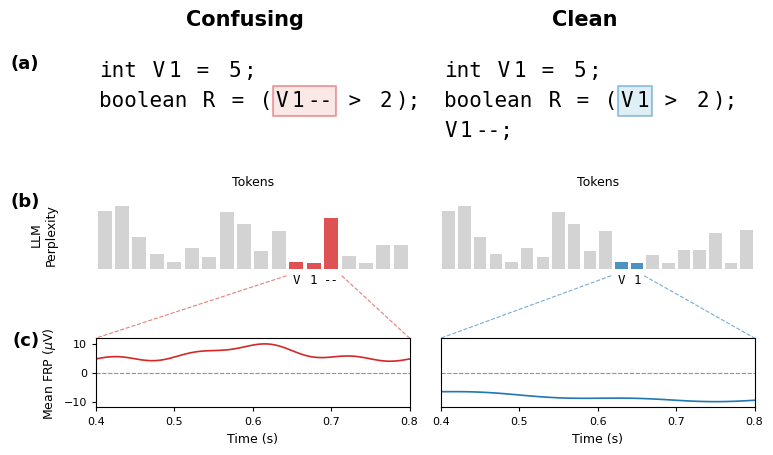

In [5]:
# ---------- Load ----------
code_clean, tokens_clean, results_clean = load_snippet(json_file, clean_key)
code_conf, tokens_conf, results_conf = load_snippet(json_file, confusing_key)

pplx_clean = get_perplexities(results_clean)
pplx_conf = get_perplexities(results_conf)

log_clean = [np.log1p(p) for p in pplx_clean]
log_conf = [np.log1p(p) for p in pplx_conf]
global_max_log = max(max(log_clean), max(log_conf))

eeg_clean = averaged_trials[clean_key][0] if averaged_trials else None
eeg_conf = averaged_trials[confusing_key][0] if averaged_trials else None

# ---------- Dynamic Figure Size ----------
num_tokens = max(len(tokens_clean), len(tokens_conf))
width = pixels_per_token * num_tokens * 2.0
width = min(width, 8.5)
height = 4.5

fig = plt.figure(figsize=(width, height))
spec = gridspec.GridSpec(ncols=2, nrows=3, figure=fig,
                         height_ratios=[1, 1, 1], hspace=1, wspace=0.1)

# Subplots
ax_code_conf = fig.add_subplot(spec[0, 0])
ax_code_clean = fig.add_subplot(spec[0, 1])
ax_pplx_conf = fig.add_subplot(spec[1, 0])
ax_pplx_clean = fig.add_subplot(spec[1, 1])
ax_eeg_conf = fig.add_subplot(spec[2, 0])
ax_eeg_clean = fig.add_subplot(spec[2, 1])

# ---------- Plot ----------
plot_code_block_with_aoi(ax_code_clean, code_clean, base_fontsize + 2, tokens_clean, highlight_ranges_clean, "clean")
plot_code_block_with_aoi(ax_code_conf, code_conf, base_fontsize + 2, tokens_conf, highlight_ranges_conf, "confusing")
plot_token_bars(ax_pplx_conf, tokens_conf, pplx_conf, bar_fontsize, highlight_ranges_conf, "confusing", label=True,
                ymax=global_max_log)
plot_token_bars(ax_pplx_clean, tokens_clean, pplx_clean, bar_fontsize, highlight_ranges_clean, "clean", label=False,
                ymax=global_max_log)
plot_eeg(ax_eeg_conf, eeg_conf, snippet_type="confusing", label=True)
plot_eeg(ax_eeg_clean, eeg_clean, snippet_type="clean", label=False)
# Clean column
if highlight_ranges_clean:
    for start, end in highlight_ranges_clean:
        draw_zoom_lines(fig, ax_pplx_clean, ax_eeg_clean, start, end, len(tokens_clean), "#1F77B4")

# Confusing column
if highlight_ranges_conf:
    for start, end in highlight_ranges_conf:
        draw_zoom_lines(fig, ax_pplx_conf, ax_eeg_conf, start, end, len(tokens_conf), "#D62728")

all_signals = np.concatenate([eeg_clean, eeg_conf])  # Combine both EEG signals for y-limits
sig_min, sig_max = all_signals.min(), all_signals.max()
abs_max = max(abs(all_signals.min()), abs(all_signals.max()))
margin = 0.1 * (sig_max - sig_min) if (sig_max - sig_min) > 0 else 0.1
for ax in (ax_eeg_clean, ax_eeg_conf):
    ax.set_ylim(-abs_max - margin, abs_max + margin)
    ax.axhline(0, color='gray', lw=0.8, linestyle='--', alpha=0.6)

# ---------- Panel Labels ----------
label_positions = [(ax_code_conf, "(a)"), (ax_pplx_conf, "(b)"), (ax_eeg_conf, "(c)")]
for ax, label in label_positions:
    ax.text(-0.18, 1.1, label, transform=ax.transAxes,
            fontsize=base_fontsize, fontweight="bold", va="top", ha="right")

fig.align_ylabels()

# Add column labels on top
fig.text(0.3, 0.95, "Confusing", fontsize=base_fontsize + 2, fontweight="bold", ha="center", va="bottom")
fig.text(0.7, 0.95, "Clean", fontsize=base_fontsize + 2, fontweight="bold", ha="center", va="bottom")

# Save the figure
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "combined_intro_plot.pdf"), dpi=300, bbox_inches='tight', pad_inches=0)